In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

I0000 00:00:1788170437.342568    5943 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1788170437.353849    5943 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1788170438.500734    5943 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1788170441.207813    5943 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.

In [6]:
df = pd.read_csv("fitness_prediction.csv")
df

,Age,Gender,Height_cm,Weight_kg,BMI,Fitness_Level,Experience_Years,Available_Days,Workout_Duration_Min,Activity_Level,Preferred_Exercise,Sleep_Hours,Daily_Steps,Recommended_Workout
0,29,Female,169.0,72.0,25.2,Advanced,2.6,4,69,High,Strength,7.0,4488,Muscle Building
1,43,Male,170.7,65.3,22.4,Advanced,0.0,4,33,Low,Cardio,9.5,5930,General Fitness
2,25,Female,169.5,62.3,21.7,Advanced,2.9,6,61,High,Cardio,6.3,9667,Endurance Training
3,51,Male,162.7,67.3,25.4,Advanced,2.7,4,48,High,Cardio,6.6,17961,Endurance Training
4,50,Female,167.1,79.0,28.3,Beginner,1.0,5,52,Low,Cardio,7.0,8227,Muscle Building
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,20,Female,159.8,82.9,32.5,Beginner,0.6,6,56,Low,Cardio,6.2,7490,Weight Loss
996,51,Male,174.1,72.8,24.0,Beginner,2.4,3,26,Moderate,Mixed,8.5,10524,General Fitness
997,33,Male,169.8,82.3,28.6,Beginner,0.7,5,52,Moderate,Cardio,6.7,7962,Weight Loss
998,50,Female,163.8,56.9,21.2,Intermediate,3.5,4,50,High,Mixed,6.2,10126,General Fitness


In [7]:
df.head()

,Age,Gender,Height_cm,Weight_kg,BMI,Fitness_Level,Experience_Years,Available_Days,Workout_Duration_Min,Activity_Level,Preferred_Exercise,Sleep_Hours,Daily_Steps,Recommended_Workout
0,29,Female,169.0,72.0,25.2,Advanced,2.6,4,69,High,Strength,7.0,4488,Muscle Building
1,43,Male,170.7,65.3,22.4,Advanced,0.0,4,33,Low,Cardio,9.5,5930,General Fitness
2,25,Female,169.5,62.3,21.7,Advanced,2.9,6,61,High,Cardio,6.3,9667,Endurance Training
3,51,Male,162.7,67.3,25.4,Advanced,2.7,4,48,High,Cardio,6.6,17961,Endurance Training
4,50,Female,167.1,79.0,28.3,Beginner,1.0,5,52,Low,Cardio,7.0,8227,Muscle Building


In [8]:
df.shape


(1000, 14)

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Age                   1000 non-null   int64  
 1   Gender                1000 non-null   str    
 2   Height_cm             1000 non-null   float64
 3   Weight_kg             1000 non-null   float64
 4   BMI                   1000 non-null   float64
 5   Fitness_Level         1000 non-null   str    
 6   Experience_Years      1000 non-null   float64
 7   Available_Days        1000 non-null   int64  
 8   Workout_Duration_Min  1000 non-null   int64  
 9   Activity_Level        1000 non-null   str    
 10  Preferred_Exercise    1000 non-null   str    
 11  Sleep_Hours           1000 non-null   float64
 12  Daily_Steps           1000 non-null   int64  
 13  Recommended_Workout   1000 non-null   str    
dtypes: float64(5), int64(4), str(5)
memory usage: 109.5 KB


In [10]:
df.isnull().sum()

Age                     0
Gender                  0
Height_cm               0
Weight_kg               0
BMI                     0
Fitness_Level           0
Experience_Years        0
Available_Days          0
Workout_Duration_Min    0
Activity_Level          0
Preferred_Exercise      0
Sleep_Hours             0
Daily_Steps             0
Recommended_Workout     0
dtype: int64

In [11]:
df.describe()

,Age,Height_cm,Weight_kg,BMI,Experience_Years,Available_Days,Workout_Duration_Min,Sleep_Hours,Daily_Steps
count,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,36.558000,165.566200,68.997700,25.10200,2.012800,4.499000,58.075000,7.002600,8095.003000
std,10.411293,8.663943,12.725325,3.78693,1.567473,1.304493,22.381651,0.997421,3476.547573
min,18.000000,145.000000,40.000000,17.50000,0.000000,2.000000,20.000000,4.500000,2501.000000
25%,28.000000,159.175000,60.275000,22.60000,0.800000,3.750000,42.000000,6.300000,5410.000000
50%,37.000000,165.700000,67.500000,24.65000,1.700000,4.000000,54.000000,7.000000,7648.500000
75%,45.000000,172.000000,76.525000,27.30000,3.000000,5.000000,73.000000,7.700000,9984.250000
max,55.000000,189.100000,120.600000,37.70000,8.600000,7.000000,120.000000,9.500000,17961.000000


In [12]:
df["Recommended_Workout"].value_counts()

Recommended_Workout
Weight Loss           277
Muscle Building       264
General Fitness       230
Endurance Training    229
Name: count, dtype: int64

In [13]:
df.duplicated().sum()

np.int64(0)

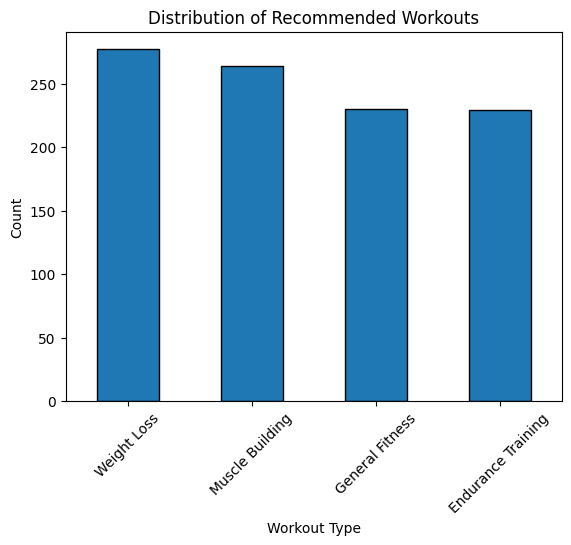

In [14]:
df["Recommended_Workout"].value_counts().plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Distribution of Recommended Workouts")
plt.xlabel("Workout Type")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

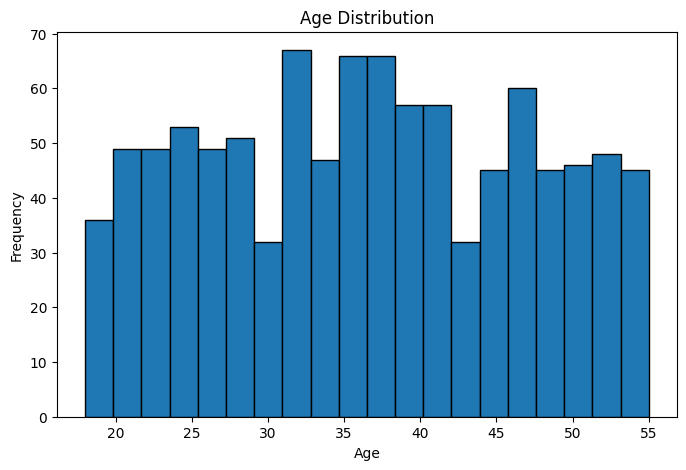

In [15]:
plt.figure(figsize=(8, 5))

plt.hist(df["Age"], bins=20, edgecolor="black")

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

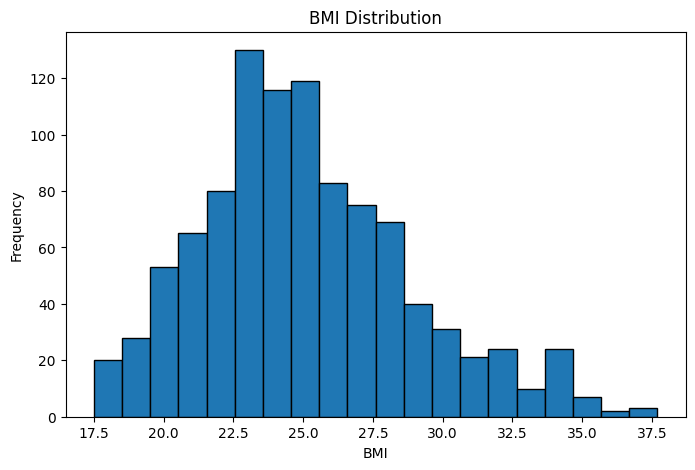

In [16]:
plt.figure(figsize=(8, 5))

plt.hist(df["BMI"], bins=20, edgecolor="black")

plt.title("BMI Distribution")
plt.xlabel("BMI")
plt.ylabel("Frequency")

plt.show()

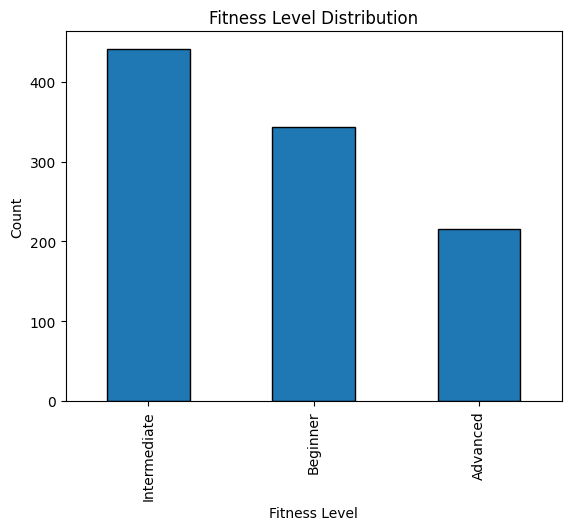

In [17]:
df["Fitness_Level"].value_counts().plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Fitness Level Distribution")
plt.xlabel("Fitness Level")
plt.ylabel("Count")

plt.show()

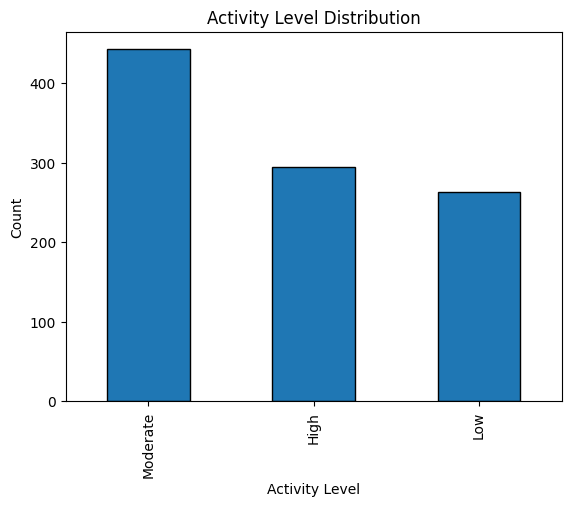

In [18]:
df["Activity_Level"].value_counts().plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Activity Level Distribution")
plt.xlabel("Activity Level")
plt.ylabel("Count")

plt.show()

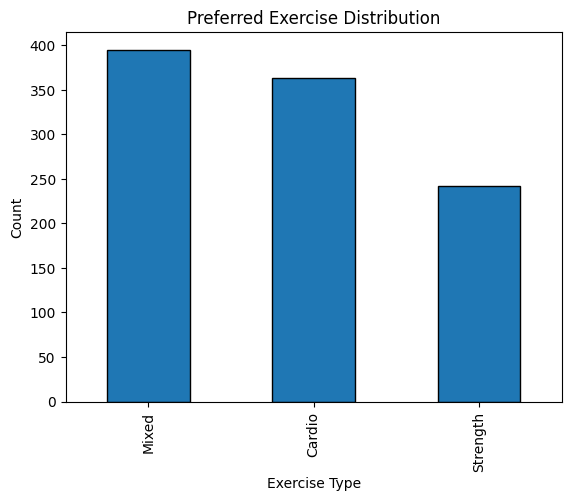

In [19]:
df["Preferred_Exercise"].value_counts().plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Preferred Exercise Distribution")
plt.xlabel("Exercise Type")
plt.ylabel("Count")

plt.show()

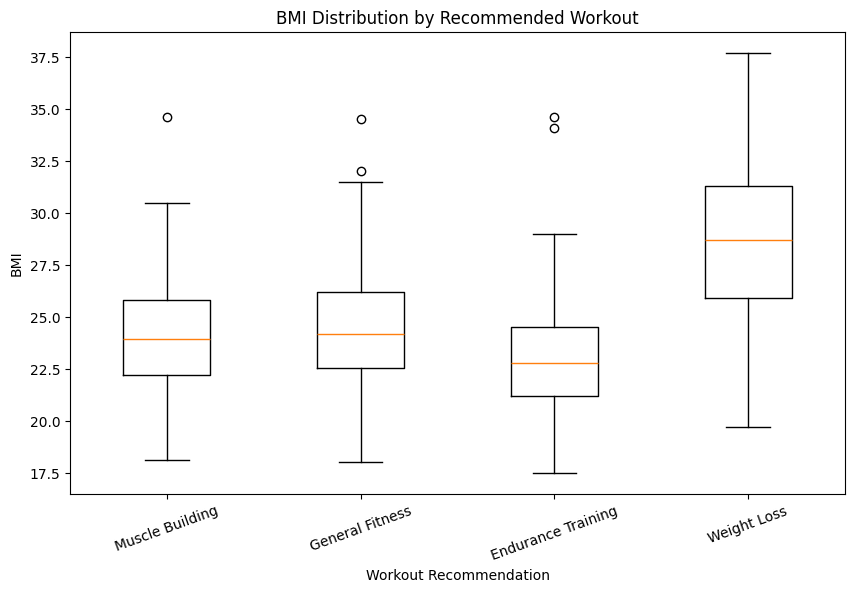

In [20]:
workout_types = df["Recommended_Workout"].unique()

bmi_by_workout = [
    df[df["Recommended_Workout"] == workout]["BMI"]
    for workout in workout_types
]

plt.figure(figsize=(10, 6))

plt.boxplot(bmi_by_workout, tick_labels=workout_types)

plt.title("BMI Distribution by Recommended Workout")
plt.xlabel("Workout Recommendation")
plt.ylabel("BMI")

plt.xticks(rotation=20)

plt.show()

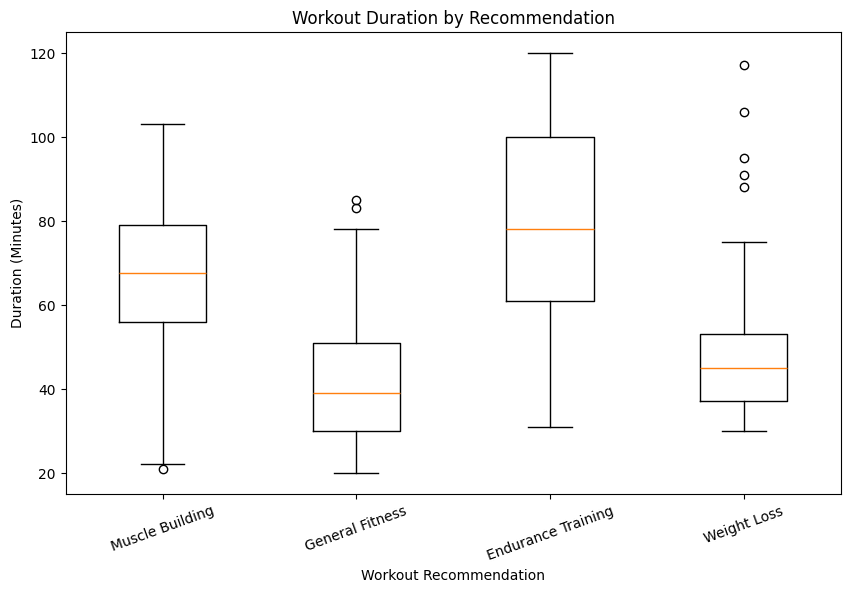

In [21]:
duration_by_workout = [
    df[df["Recommended_Workout"] == workout]["Workout_Duration_Min"]
    for workout in workout_types
]

plt.figure(figsize=(10, 6))

plt.boxplot(duration_by_workout, tick_labels=workout_types)

plt.title("Workout Duration by Recommendation")
plt.xlabel("Workout Recommendation")
plt.ylabel("Duration (Minutes)")

plt.xticks(rotation=20)

plt.show()

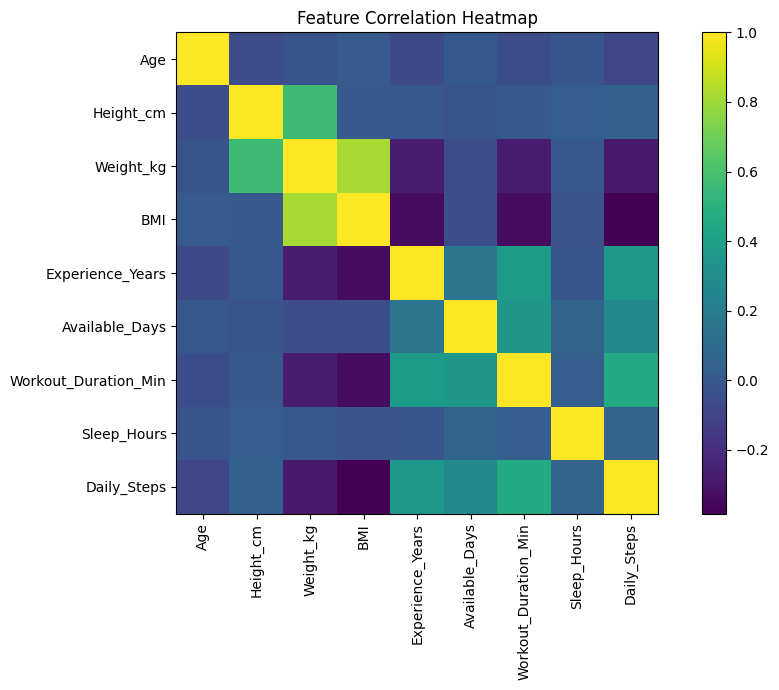

In [22]:
numeric_df = df.select_dtypes(include=np.number)

correlation = numeric_df.corr()

plt.figure(figsize=(10, 7))

plt.imshow(correlation)

plt.colorbar()

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=90
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title("Feature Correlation Heatmap")

plt.tight_layout()

plt.show()

In [23]:
X = df.drop("Recommended_Workout", axis=1)

y = df["Recommended_Workout"]

In [24]:
print(X.shape)
print(y.shape)

(1000, 13)
(1000,)


In [25]:
categorical_cols = X.select_dtypes(include="object").columns

print(categorical_cols)

Index(['Gender', 'Fitness_Level', 'Activity_Level', 'Preferred_Exercise'], dtype='str')


/tmp/ipykernel_5943/1036235728.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(include="object").columns


In [26]:
X = pd.get_dummies(
    X,
    columns=categorical_cols,
    drop_first=True
)

In [27]:
X.head()

,Age,Height_cm,Weight_kg,BMI,Experience_Years,Available_Days,Workout_Duration_Min,Sleep_Hours,Daily_Steps,Gender_Male,Fitness_Level_Beginner,Fitness_Level_Intermediate,Activity_Level_Low,Activity_Level_Moderate,Preferred_Exercise_Mixed,Preferred_Exercise_Strength
0,29,169.0,72.0,25.2,2.6,4,69,7.0,4488,False,False,False,False,False,False,True
1,43,170.7,65.3,22.4,0.0,4,33,9.5,5930,True,False,False,True,False,False,False
2,25,169.5,62.3,21.7,2.9,6,61,6.3,9667,False,False,False,False,False,False,False
3,51,162.7,67.3,25.4,2.7,4,48,6.6,17961,True,False,False,False,False,False,False
4,50,167.1,79.0,28.3,1.0,5,52,7.0,8227,False,True,False,True,False,False,False


In [28]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

In [29]:
print(label_encoder.classes_)
print(y_encoded[:10])
for i, class_name in enumerate(label_encoder.classes_):
    print(f"{class_name} → {i}")

['Endurance Training' 'General Fitness' 'Muscle Building' 'Weight Loss']
[2 1 0 0 2 3 3 1 0 0]
Endurance Training → 0
General Fitness → 1
Muscle Building → 2
Weight Loss → 3


In [30]:
loss="sparse_categorical_crossentropy"

In [31]:
print(X.shape)

(1000, 16)


In [32]:
# Separate features and target

X = df.drop("Recommended_Workout", axis=1)
y = df["Recommended_Workout"]


# Find categorical columns

categorical_cols = X.select_dtypes(include="object").columns

print("Categorical columns:")
print(categorical_cols)


# One-Hot Encode input categorical features

X = pd.get_dummies(
    X,
    columns=categorical_cols,
    drop_first=True
)


# Encode target

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)


# Display target mapping

for i, class_name in enumerate(label_encoder.classes_):
    print(f"{class_name} → {i}")


print("\nFinal Feature Shape:", X.shape)

Categorical columns:
Index(['Gender', 'Fitness_Level', 'Activity_Level', 'Preferred_Exercise'], dtype='str')
Endurance Training → 0
General Fitness → 1
Muscle Building → 2
Weight Loss → 3

Final Feature Shape: (1000, 16)


/tmp/ipykernel_5943/2241462101.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(include="object").columns


In [41]:
from sklearn.model_selection import train_test_split
# Convert features to numeric
X = X.astype(float)


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)


# Check shapes

print("X_train:", X_train_scaled.shape)
print("X_test:", X_test_scaled.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)
#from sklearn.model_selection import train_test_split

X_train: (800, 16)
X_test: (200, 16)
y_train: (800,)
y_test: (200,)


In [42]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (800, 16)
X_test shape: (200, 16)
y_train shape: (800,)
y_test shape: (200,)


In [43]:
#ANN CODE 
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense


model = Sequential([

    Dense(
        32,
        activation="relu",
        input_shape=(X_train_scaled.shape[1],)
    ),

    Dense(16, activation="relu"),

    Dense(8, activation="relu"),

    Dense(
        4,
        activation="softmax"
    )
])


model.summary()

/home/kniti/Downloads/ADS/myenv/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
E0000 00:00:1788171057.271657    5943 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │            36 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,244 (4.86 KB)

 Trainable params: 1,244 (4.86 KB)

 Non-trainable params: 0 (0.00 B)

In [44]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [45]:
history = model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    verbose=1
)

Epoch 1/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.3391 - loss: 1.4250 - val_accuracy: 0.3812 - val_loss: 1.3015
Epoch 2/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4156 - loss: 1.2744 - val_accuracy: 0.4500 - val_loss: 1.2070
Epoch 3/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.4719 - loss: 1.1720 - val_accuracy: 0.5188 - val_loss: 1.1157
Epoch 4/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5109 - loss: 1.0853 - val_accuracy: 0.5625 - val_loss: 1.0298
Epoch 5/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5297 - loss: 1.0064 - val_accuracy: 0.6187 - val_loss: 0.9621
Epoch 6/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5469 - loss: 0.9425 - val_accuracy: 0.6375 - val_loss: 0.9117
Epoch 7/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5781 - loss: 0.8906 - val_accuracy: 0.6812 - val_loss: 0.8777
Epoch 8/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6391 - loss: 0.8475 - val_accuracy: 0.7063 - val_loss

In [46]:
test_loss, test_accuracy = model.evaluate(
    X_test_scaled,
    y_test
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8700 - loss: 0.4773  
Test Loss: 0.4772736430168152
Test Accuracy: 0.8700000047683716


In [49]:
y_pred_prob = model.predict(X_test_scaled)

print(y_pred_prob[:5])

np.set_printoptions(suppress=True, precision=4)

print(y_pred_prob[:5])

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
[[2.1070018e-03 1.2578484e-02 4.5265509e-03 9.8078799e-01]
 [3.3147343e-02 6.1719853e-01 2.7538853e-02 3.2211524e-01]
 [9.9206442e-01 3.4595239e-03 4.1958881e-03 2.8018389e-04]
 [5.0494261e-04 5.1470047e-06 9.9948478e-01 5.1551001e-06]
 [6.4721494e-03 2.1902530e-01 1.1487707e-02 7.6301491e-01]]
[[0.0021 0.0126 0.0045 0.9808]
 [0.0331 0.6172 0.0275 0.3221]
 [0.9921 0.0035 0.0042 0.0003]
 [0.0005 0.     0.9995 0.    ]
 [0.0065 0.219  0.0115 0.763 ]]


In [48]:
y_pred = np.argmax(y_pred_prob, axis=1)

print(y_pred[:10])

[3 1 0 2 3 0 1 1 1 0]


In [50]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=label_encoder.classes_
))

                    precision    recall  f1-score   support

Endurance Training       0.95      0.87      0.91        46
   General Fitness       0.83      0.87      0.85        46
   Muscle Building       0.85      0.85      0.85        53
       Weight Loss       0.86      0.89      0.88        55

          accuracy                           0.87       200
         macro avg       0.87      0.87      0.87       200
      weighted avg       0.87      0.87      0.87       200



In [51]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[40  1  3  2]
 [ 0 40  4  2]
 [ 2  2 45  4]
 [ 0  5  1 49]]


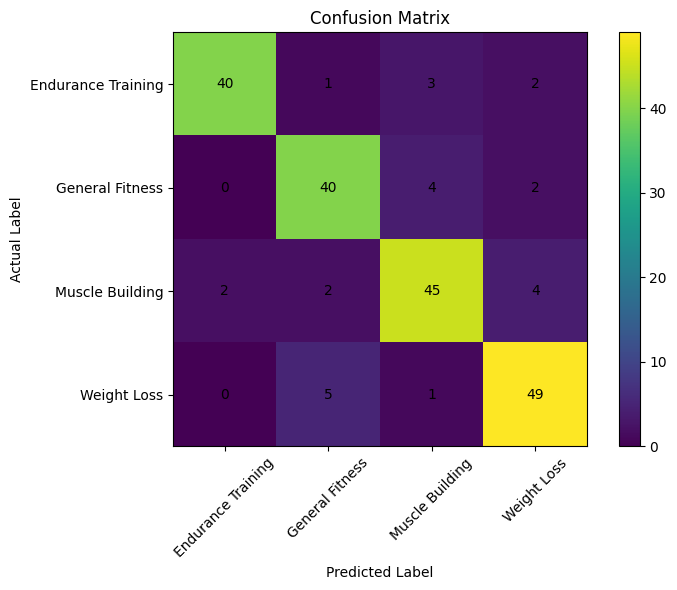

In [52]:
plt.figure(figsize=(8, 6))

plt.imshow(cm)

plt.colorbar()

plt.xticks(
    range(len(label_encoder.classes_)),
    label_encoder.classes_,
    rotation=45
)

plt.yticks(
    range(len(label_encoder.classes_)),
    label_encoder.classes_
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")

# Add numbers inside each cell
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(
            j, i, cm[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

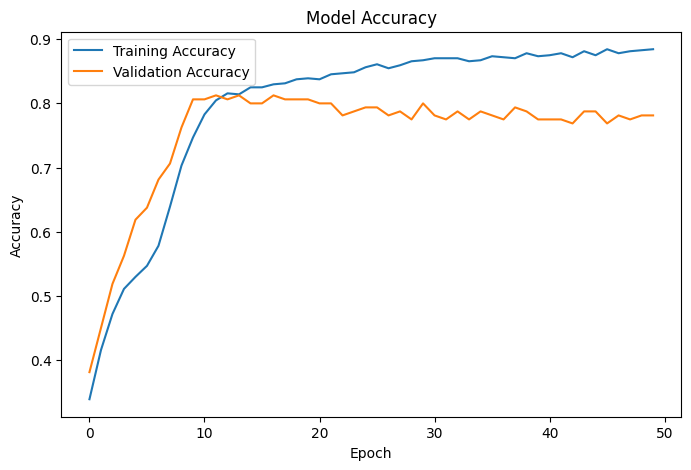

In [54]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.show()

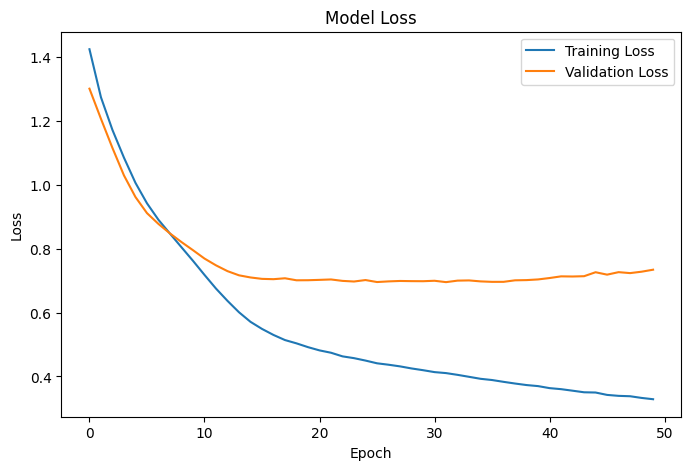

In [55]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.show()

In [59]:
# Create new user
new_user = pd.DataFrame([{
    "Age": 23,
    "Gender": "Male",
    "Height_cm": 175,
    "Weight_kg": 78,
    "BMI": 25.5,
    "Fitness_Level": "Intermediate",
    "Experience_Years": 2,
    "Available_Days": 5,
    "Workout_Duration_Min": 60,
    "Activity_Level": "Moderate",
    "Preferred_Exercise": "Strength",
    "Sleep_Hours": 7,
    "Daily_Steps": 7000
}])


# One-hot encode
new_user_encoded = pd.get_dummies(new_user)


# Match training feature columns
new_user_encoded = new_user_encoded.reindex(
    columns=X.columns,
    fill_value=0
)


# Scale
new_user_scaled = scaler.transform(new_user_encoded)


# Predict
prediction_prob = model.predict(new_user_scaled)


# Get predicted class
prediction_class = np.argmax(prediction_prob, axis=1)


# Convert class back to name
predicted_workout = label_encoder.inverse_transform(
    prediction_class
)


print("Recommended Workout:", predicted_workout[0])
print("Confidence:", round(np.max(prediction_prob) * 100, 2), "%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
Recommended Workout: Muscle Building
Confidence: 84.91 %
